In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv('units_L234.csv').copy()

In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['strategy_dendrite', 'pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

In [4]:
units_cleaned = clean_dataset(units)

In [5]:
mask_exc = (units_cleaned['classification_system'] == 'excitatory_neuron')
mask_inh = (units_cleaned['classification_system'] == 'inhibitory_neuron')

mask_l23 = (units_cleaned['layer'] == 'L2/3')
mask_l4 = (units_cleaned['layer'] == 'L4')

In [6]:
E_L23 = units_cleaned[mask_exc & mask_l23].copy().reset_index(drop=True)
I_L23 = units_cleaned[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = units_cleaned[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = units_cleaned[mask_inh & mask_l4].copy().reset_index(drop=True)

In [7]:
len(E_L23), len(I_L23), len(E_L4), len(I_L4)

(13157, 1299, 9487, 828)

In [8]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

# Connection Probability vs Inter-Somatic Distance

In [9]:
def existing_connections(
    path_name, pre_pop, post_pop,
    syn, metric='Euclidean'
):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if metric == 'Euclidean':
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if metric == 'Euclidean':
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    return conn

In [10]:
def potential_connections(pre_pop, post_pop, metric='Euclidean'):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if metric == 'Euclidean':
        feat_to_keep.append('pt_position_y')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # --- cartesian product --- all_pairs = pre.merge(postn how='cross') probably easier ;D
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # --- rimuove self-connections ---
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    # --- distanze riga per riga ---
    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if metric == 'Euclidean':
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    all_pairs['size'] = 0.0

    return all_pairs

In [11]:
def compute_connection_probability(conn, pot, value_column, bins):
    syn_counts, _ = np.histogram(conn[value_column], bins=bins)
    pot_counts, _ = np.histogram(pot[value_column], bins=bins)

    prob = np.divide(
        syn_counts, pot_counts,
        out=np.zeros_like(syn_counts, dtype=float),
        where=pot_counts != 0
    )

    # Binomial SEM
    sem_prob = np.sqrt(prob * (1 - prob) / pot_counts)
    sem_prob[pot_counts == 0] = np.nan

    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    return bin_centers, prob, sem_prob

In [12]:
res_exp_con_prob_vs_distance = {}

dist_bins = np.linspace(0, 400, 10)

for path, pre, post in pathways:
    conn = existing_connections(path, pre, post, synapses, metric='Euclidean')
    pot = potential_connections(pre, post, metric='Euclidean')

    c, p, s = compute_connection_probability(conn, pot, 'euclidean', dist_bins)
    res_exp_con_prob_vs_distance[path] = (c, p, s)

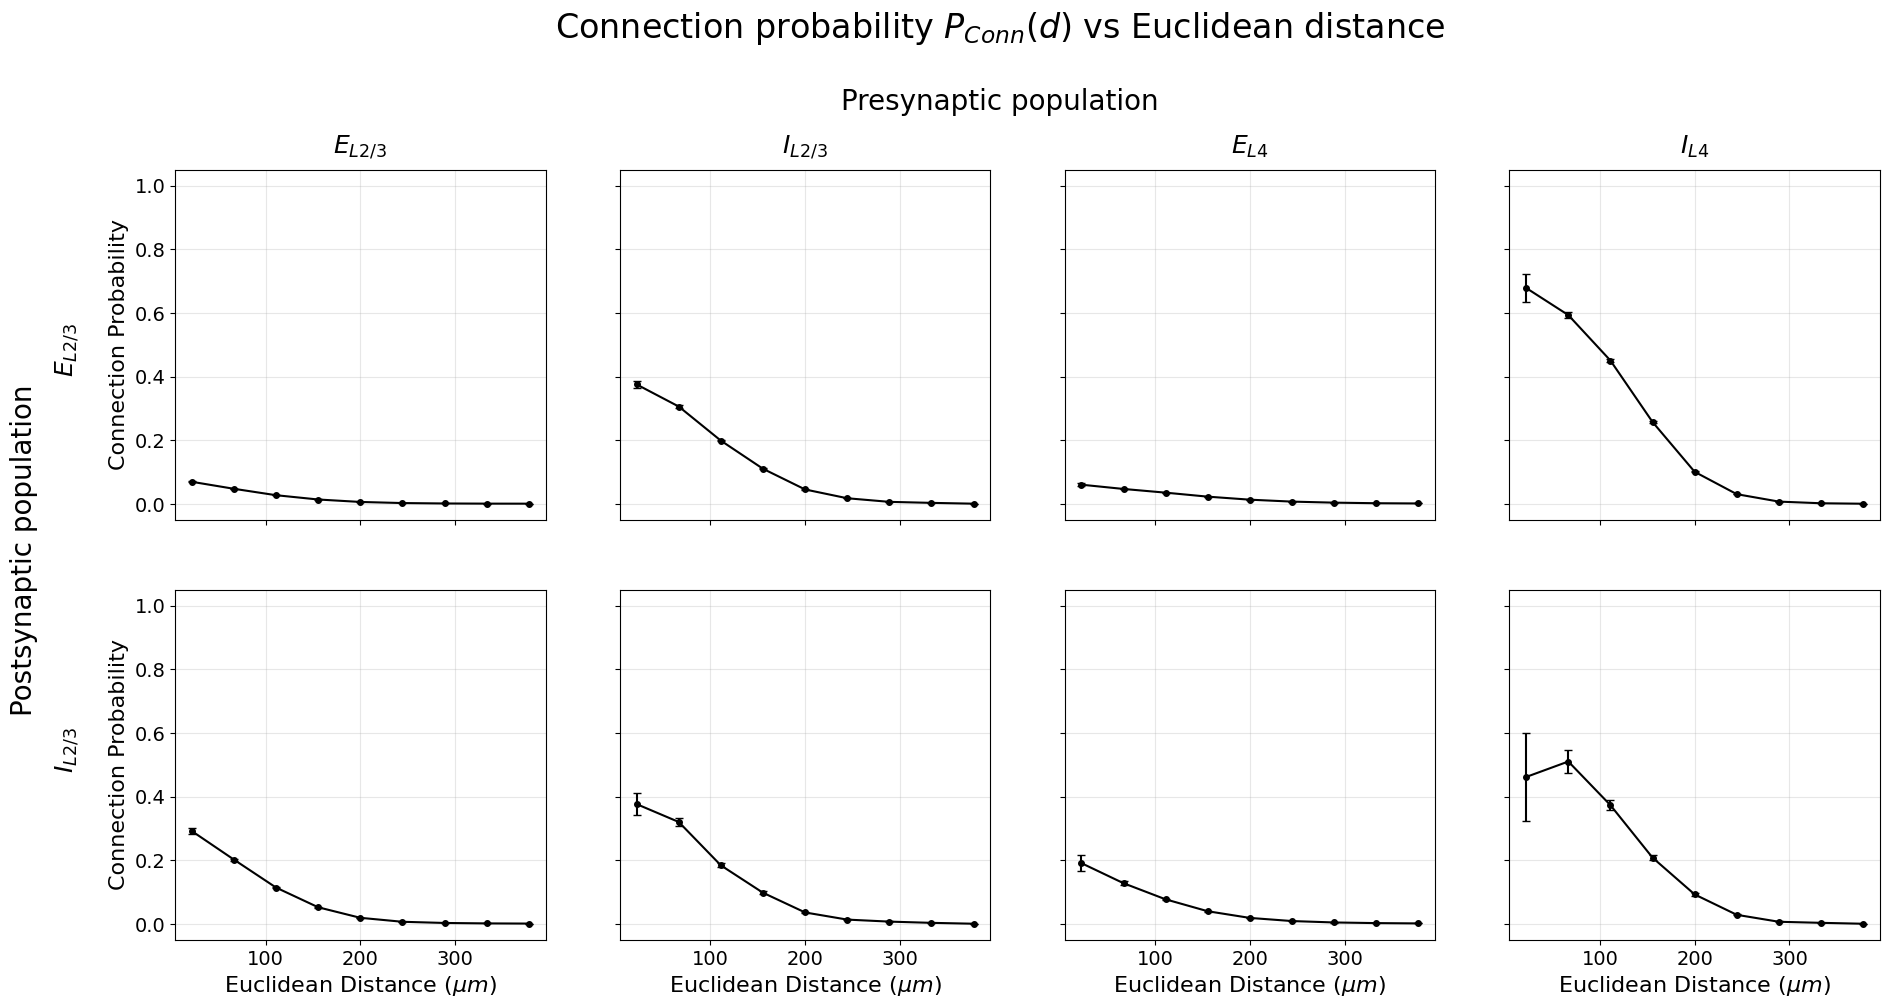

In [13]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(res_exp_con_prob_vs_distance.items()):
    row = i // 4
    col = i % 4

    centers_emp, prob_emp, sem_emp = prob

    axs[row, col].errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=4,
        linewidth=1.5,
        capsize=3
    )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')
    axs[row, col].set_ylim(-0.05, 1.05)

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Connection Probability", fontsize=16)
axs[1, 0].set_ylabel("Connection Probability", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Connection probability $P_{Conn}(d)$ vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_Euclidean.png", dpi=300)
plt.show()

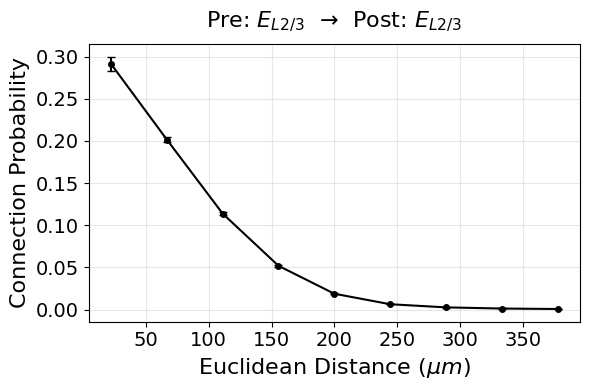

In [14]:
first_key = list(res_exp_con_prob_vs_distance.keys())[4]
centers_emp, prob_emp, sem_emp = res_exp_con_prob_vs_distance[first_key]

fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(
    centers_emp,
    prob_emp,
    yerr=sem_emp,
    color='black',
    linestyle='-',
    marker='o',
    markersize=4,
    linewidth=1.5,
    capsize=3
)

ax.grid(alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.set_facecolor('white')
#ax.set_ylim(-0.05, 1.05)

ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)
ax.set_ylabel("Connection Probability", fontsize=16)

ax.set_title(
    r"Pre: $E_{L2/3}$  →  Post: $E_{L2/3}$", # E_{L2/3} -> I_{L2/3} instead look at pathways
    fontsize=16, pad=12
)

plt.tight_layout()
plt.show()

# Synaptic Volume vs Inter-Somatic Distance

In [15]:
from scipy.stats import sem


def make_syn_df(values, feature_name, sizes):
    df = pd.DataFrame({feature_name: values, 'size': sizes})
    return df.copy()


def compute_synapse_size_statistics(paired_df, value_column, bins):
    """
    Computes mean synapse size and SEM across binned feature values.

    Parameters:
        paired_df (DataFrame): Contains actual synapses with 'size' column.
        value_column (str): Feature used for binning.
        bins (np.array): Bin edges.

    Returns:
        bin_centers, mean_size, sem_size
    """
    mean_size = []
    sem_size = []

    for i in range(len(bins) - 1):
        in_bin = (paired_df[value_column] >= bins[i]) & (paired_df[value_column] < bins[i + 1])
        sizes = paired_df.loc[in_bin, 'size']
        mean_size.append(sizes.mean() if not sizes.empty else 0)
        sem_size.append(sem(sizes) if not sizes.empty else np.nan)

    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    return bin_centers, mean_size, sem_size


def compute_heatmap_manual(fw, x_col, y_col, bins_num_x=400, bins_num_y=400, x_range = [0,300], y_range = [0,3]):
    #d95_x = np.quantile(fw["euclidean"], 0.95)
    #d95_y = np.quantile(fw["size"], 0.95)
    bins_x = np.linspace(x_range[0], x_range[1], bins_num_x)
    bins_y = np.linspace(y_range[0], y_range[1], bins_num_y)
    
    ix = np.searchsorted(bins_x, fw[x_col], side="right") - 1
    iy = np.searchsorted(bins_y, fw[y_col], side="right") - 1

    valid = (
        (ix >= 0) & (ix < len(bins_x) - 1) &
        (iy >= 0) & (iy < len(bins_y) - 1)
    )

    heatmap = np.zeros((len(bins_x)-1, len(bins_y)-1))

    np.add.at(heatmap, (ix[valid], iy[valid]), 1)

    return heatmap, bins_x, bins_y

In [16]:
emp_dict = {}
emp_size_euc = {}

emp_heatmap = {}

for path, pre, post in pathways:

    conn = existing_connections(path, pre, post, synapses)
    pot = potential_connections(pre, post)

    den = pd.concat([conn, pot], ignore_index=True)

    emp_dict[path] = den

for path, connection in emp_dict.items():

    if connection.empty:
        print(f"Skipping {path} (empty empirical data)")
        continue

    cols = ["euclidean", "size"]
    if not all(col in connection.columns for col in cols):
        print(f"Missing columns in {path}, skipping.")
        continue

    mask_syn = connection["size"] > 0
    if not mask_syn.any():
        print(f"No synapses found in empirical {path}, skipping.")
        continue

    syn = connection.loc[mask_syn, cols].reset_index(drop=True)

    # --- Euclidean ---
    df_euc = make_syn_df(syn["euclidean"], "euclidean", syn["size"])
    c, m, s = compute_synapse_size_statistics(df_euc, "euclidean", dist_bins)
    emp_heatmap[path] = compute_heatmap_manual(df_euc, "euclidean", "size", 30, 30)
    emp_size_euc[path] = (c, np.array(m), np.array(s))

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_101856\2962432704.py:28: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem_size.append(sem(sizes) if not sizes.empty else np.nan)
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_101856\2962432704.py:28: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  sem_size.append(sem(sizes) if not sizes.empty else np.nan)


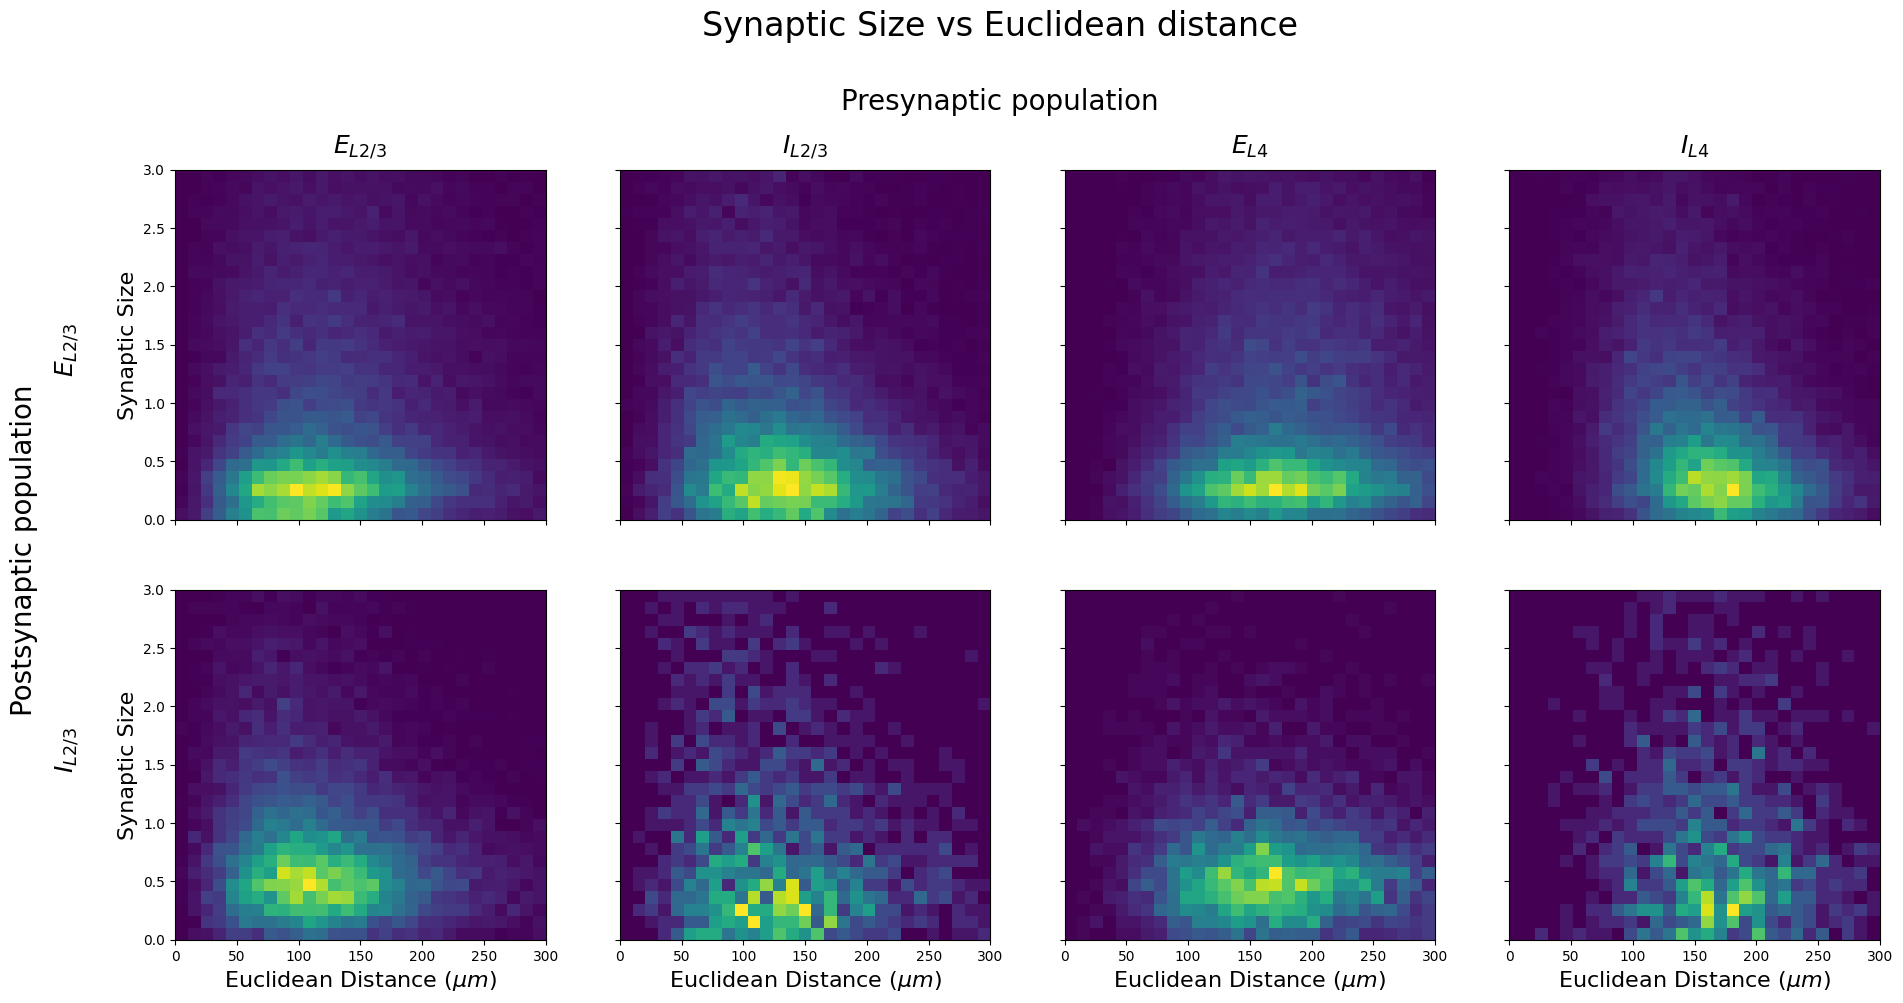

<Figure size 640x480 with 0 Axes>

In [17]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(emp_heatmap.items()):
    row = i // 4
    col = i % 4

    heatmap, x, y = prob
    ax = axs[row, col]
    ax.pcolormesh(
    x,
    y,
    heatmap.T,
    shading="auto"
    )   

for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Synaptic Size", fontsize=16)
axs[1, 0].set_ylabel("Synaptic Size", fontsize=16)


# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Synaptic Size vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()
fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Synaptic Size vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()


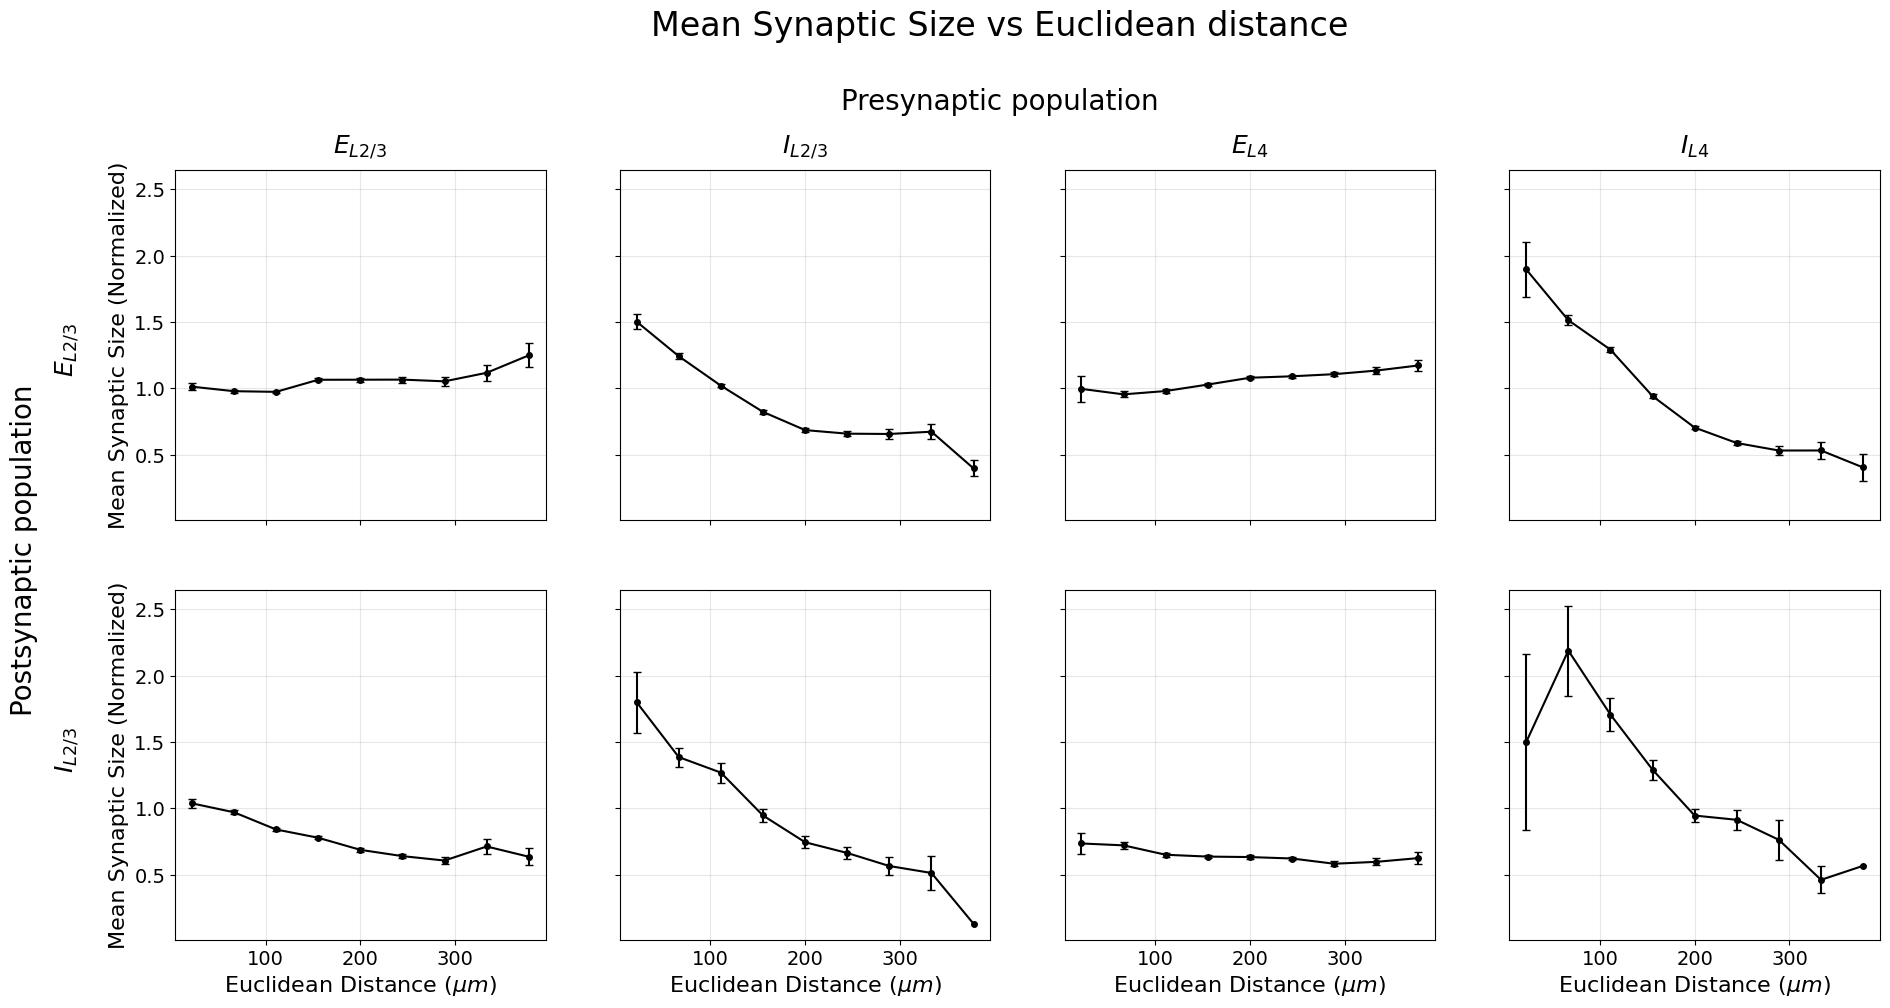

<Figure size 640x480 with 0 Axes>

In [18]:




fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(emp_size_euc.items()):
    row = i // 4
    col = i % 4

    centers_emp, prob_emp, sem_emp = prob

    axs[row, col].errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=4,
        linewidth=1.5,
        capsize=3
    )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=16)
axs[1, 0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Mean Synaptic Size vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()
fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Mean Synaptic Size vs Euclidean distance",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()

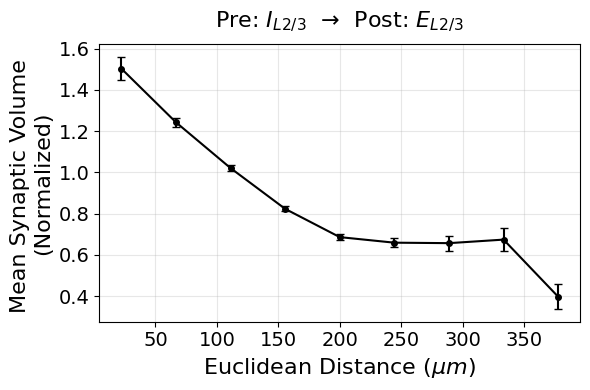

In [19]:
first_key = list(emp_size_euc.keys())[1]
centers_emp, prob_emp, sem_emp = emp_size_euc[first_key]

fig, ax = plt.subplots(figsize=(6, 4))

ax.errorbar(
    centers_emp,
    prob_emp,
    yerr=sem_emp,
    color='black',
    linestyle='-',
    marker='o',
    markersize=4,
    linewidth=1.5,
    capsize=3
)

ax.grid(alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.set_facecolor('white')

ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)
ax.set_ylabel("Mean Synaptic Volume \n(Normalized)", fontsize=16)

ax.set_title(
    r"Pre: $I_{L2/3}$  →  Post: $E_{L2/3}$",
    fontsize=16, pad=12
)

plt.tight_layout()
plt.savefig("size_1.png", dpi=500)
plt.show()

# Connection Probability vs Preferred Orientation Difference

In [20]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [21]:
def existing_connections_ori(
    path_name, pre_pop, post_pop,
    syn, metric='Ori_Diff'
):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    mask_sel_pre = pre_pop['selective_ori'] == 'True'
    mask_sel_post = post_pop['selective_ori'] == 'True'

    pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
    post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pref_ori_fit',
    ]

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns = lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns = lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    ori_pre = conn['pre_pref_ori_fit'].to_numpy()
    ori_post = conn['post_pref_ori_fit'].to_numpy()

    conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)

    return conn

In [22]:
def potential_connections_ori(pre_pop, post_pop):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    mask_sel_pre = pre_pop['selective_ori'] == 'True'
    mask_sel_post = post_pop['selective_ori'] == 'True'

    pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
    post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

    feat_to_keep = ['pt_root_id', 'pref_ori_fit']

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    # Compute orientation difference row-wise
    ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
    ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

    all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)

    return all_pairs

In [23]:
pathways1 = [
    ('E23_E23', E_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [24]:
res = {}

ori_bins = np.linspace(-np.pi/2, np.pi/2, 10)

for path, pre, post in pathways1:
    conn = existing_connections_ori(path, pre, post, synapses)
    pot = potential_connections_ori(pre, post)

    c, p, s = compute_connection_probability(conn, pot, 'ori_diff', ori_bins)
    res[path] = (c, p, s)

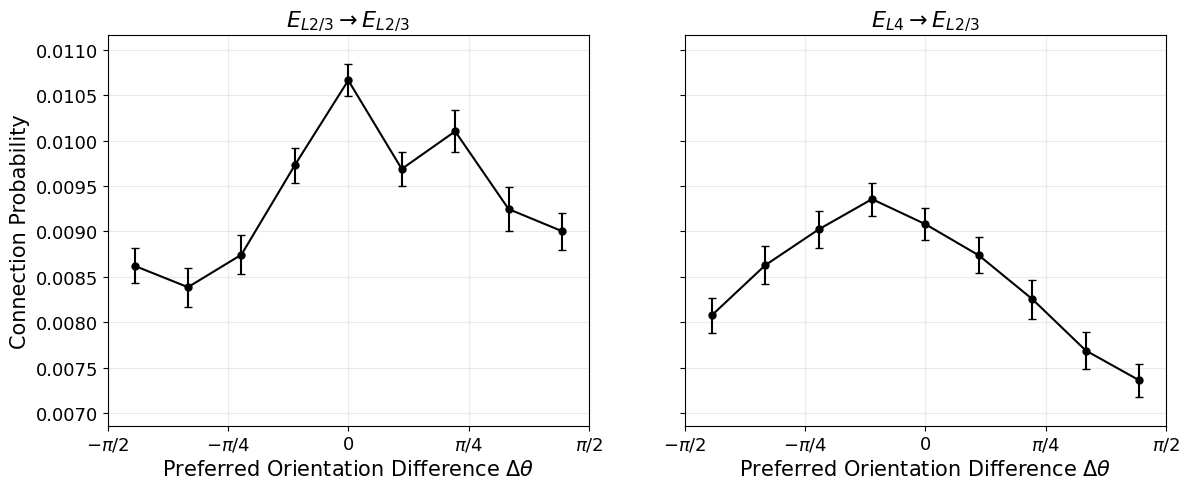

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (path, prob) in zip(axs, res.items()):

    centers_emp, prob_emp, sem_emp = prob

    ax.errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=5,
        linewidth=1.5,
        capsize=3
    )

    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=13)
    ax.set_facecolor('white')

    ax.set_xlim(-np.pi/2, np.pi/2)
    ax.set_xticks(
        [-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2]
    )
    ax.set_xticklabels(
        [r"$-\pi/2$", r"$-\pi/4$", r"$0$", r"$\pi/4$", r"$\pi/2$"]
    )

all_probs = np.concatenate([res[k][1] for k in res])
ymin = all_probs.min()
ymax = all_probs.max()

margin = 0.0005
axs[0].set_ylim(ymin - margin, ymax + margin)

# ---- labels
axs[0].set_ylabel("Connection Probability", fontsize=15)

for ax in axs:
    ax.set_xlabel(r"Preferred Orientation Difference $\Delta\theta$", fontsize=15)

# ---- titles
axs[0].set_title(r"$E_{L2/3} \rightarrow E_{L2/3}$", fontsize=16)
axs[1].set_title(r"$E_{L4} \rightarrow E_{L2/3}$", fontsize=16)


plt.tight_layout()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_OriDiff_clean.png", dpi=300)
plt.show()

# Synaptic Volume vs Preferred Orientation Difference

In [26]:
emp_dict = {}
emp_size_euc = {}
emp_heatmap = {}

for path, pre, post in pathways1:

    conn = existing_connections_ori(path, pre, post, synapses)
    pot = potential_connections_ori(pre, post)

    den = pd.concat([conn, pot], ignore_index=True)

    emp_dict[path] = den

for path, connection in emp_dict.items():

    if connection.empty:
        print(f"Skipping {path} (empty empirical data)")
        continue

    cols = ["ori_diff", "size"]
    if not all(col in connection.columns for col in cols):
        print(f"Missing columns in {path}, skipping.")
        continue

    mask_syn = connection["size"] > 0
    if not mask_syn.any():
        print(f"No synapses found in empirical {path}, skipping.")
        continue

    syn = connection.loc[mask_syn, cols].reset_index(drop=True)

    # --- Euclidean ---
    df_ori = make_syn_df(syn["ori_diff"], "ori_diff", syn["size"])
    c, m, s = compute_synapse_size_statistics(df_ori, "ori_diff", ori_bins)
    emp_heatmap[path] = compute_heatmap_manual(df_ori, "ori_diff", "size", 50, 50, [-np.pi/2, np.pi/2], [0,3])
    emp_size_euc[path] = (c, np.array(m), np.array(s))

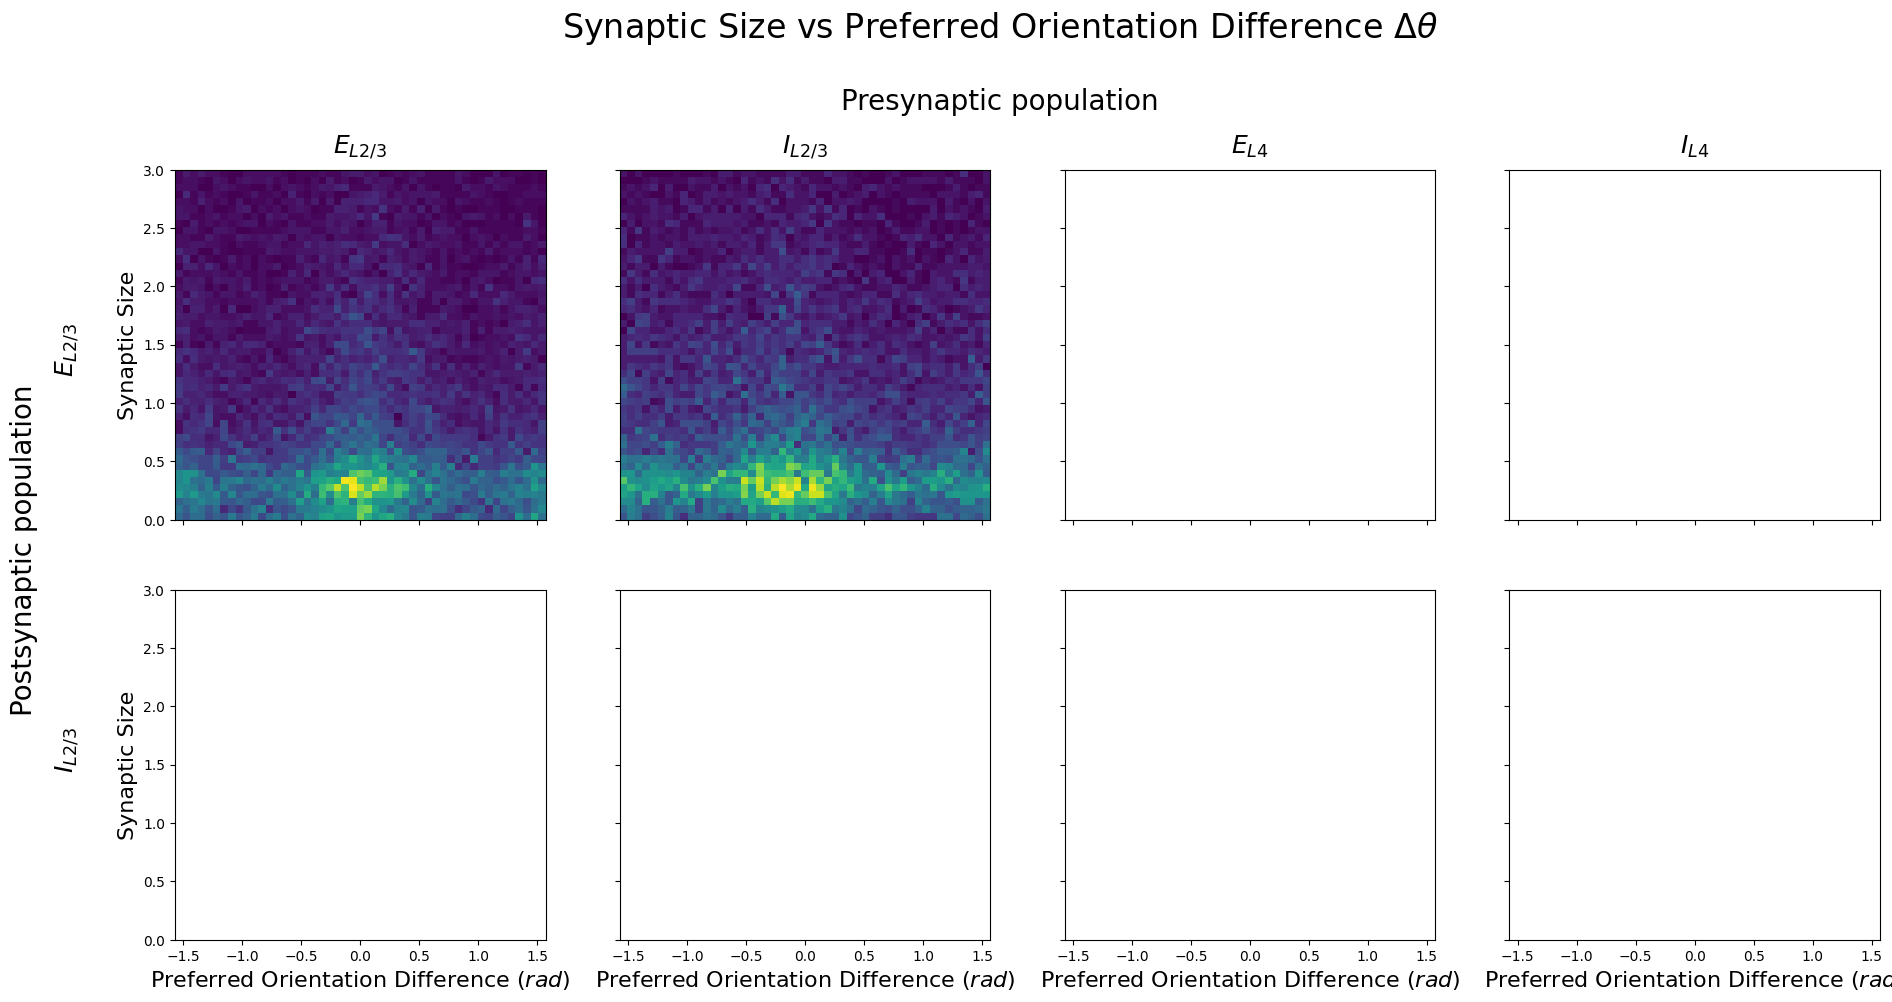

<Figure size 640x480 with 0 Axes>

In [27]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)

# -----------------------
# plotting
# -----------------------
for i, (path, prob) in enumerate(emp_heatmap.items()):
    row = i // 4
    col = i % 4

    heatmap, x, y = prob
    ax = axs[row, col]
    ax.pcolormesh(
    x,
    y,
    heatmap.T,
    shading="auto"
    )   

for ax in axs[1, :]:
    ax.set_xlabel(r"Preferred Orientation Difference ($rad$)", fontsize=16)

axs[0, 0].set_ylabel("Synaptic Size", fontsize=16)
axs[1, 0].set_ylabel("Synaptic Size", fontsize=16)


# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Synaptic Size vs Preferred Orientation Difference $\Delta\theta$",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()
fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Synaptic Size vs Preferred Orientation Difference $\Delta\theta$",
    fontsize=24,
    y=1.04
)

fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_Euc.png", dpi=300)
plt.show()


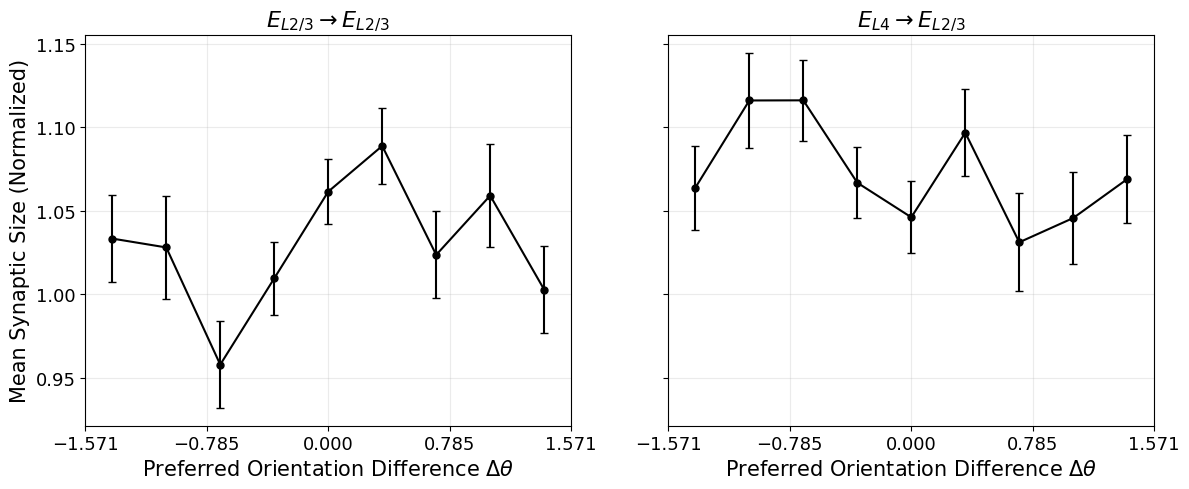

In [28]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (path, prob) in zip(axs, emp_size_euc.items()):

    centers_emp, prob_emp, sem_emp = prob

    ax.errorbar(
        centers_emp,
        prob_emp,
        yerr=sem_emp,
        color='black',
        linestyle='-',
        marker='o',
        markersize=5,
        linewidth=1.5,
        capsize=3
    )

    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=13)
    ax.set_facecolor('white')

    ax.set_xlim(-np.pi/2, np.pi/2)
    ax.set_xticks(
        [-np.pi/2, -np.pi/4, 0, np.pi/4, np.pi/2]
    )

# ---- labels
axs[0].set_ylabel("Mean Synaptic Size (Normalized)", fontsize=15)

for ax in axs:
    ax.set_xlabel(r"Preferred Orientation Difference $\Delta\theta$", fontsize=15)

# ---- titles
axs[0].set_title(r"$E_{L2/3} \rightarrow E_{L2/3}$", fontsize=16)
axs[1].set_title(r"$E_{L4} \rightarrow E_{L2/3}$", fontsize=16)


plt.tight_layout()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("Size_OriDiff.png", dpi=300)
plt.show()

# Simple MLP Pipeline

In [29]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [30]:
def existing_connections_v1(
    path_name, pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [31]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs = all_pairs.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [32]:
global pot1

def build_dataset(pre_pop, post_pop, synapses, metric=['Euclidean']):
    """
    Builds a DataFrame with features and labels for a given pathway.
    """
    #Get the connections and the potential pairs.
    
    conn_dist = existing_connections_v1("temp", pre_pop, post_pop, synapses, metric)
    print(conn_dist)
    
    pot_dist = potential_connections_v1(pre_pop, post_pop, metric)
    #pot_dist = pot_dist.sample(n=len(conn_dist) * 3, random_state=42).copy()  # ratio 1:10

    conn_dist = conn_dist.copy()
    pot_dist = pot_dist.copy()

    conn_dist['label'] = 1
    pot_dist['label'] = 0

    df = pd.concat([conn_dist, pot_dist], ignore_index=True)

    df = df.drop_duplicates(
        subset=['pre_pt_root_id', 'post_pt_root_id'],
        keep='first'   # garde conn_dist car on l’a mis en premier
    )

    #df = df[df['label'] == 1]


    """conn_ori = existing_connections_ori("temp", pre_pop, post_pop, synapses, metric='Euclidean')
    pot_ori = potential_connections_ori(pre, post)

    conn_ori = conn_ori.drop(columns=[
        'size'
    ])

    conn = conn_dist.merge(conn_ori, on=["pre_pt_root_id", "post_pt_root_id"], how="inner")
    pot = pot_dist.merge(pot_ori, on=["pre_pt_root_id", "post_pt_root_id"], how="inner")
    global pot1
    pot1 = pot.copy()

    print(len(pot))
    pot = pot[~pot.set_index(['pre_pt_root_id','post_pt_root_id']).index.isin(
    conn.set_index(['pre_pt_root_id','post_pt_root_id']).index
    )].reset_index(drop=True)
    print(len(pot))"""

    # Ajouter le label
    #conn['label'] = 1
    #pot['label'] = 0

    #SIMPLE NEGATIVE DOWNSAMPLING
    #n_pos = len(conn)
    #pot = pot.sample(n=n_pos * 2, random_state=42).copy()  # ratio 1:10

    #print(conn)
    #print(pot)
    
    # Concaténer
    #df = pd.concat([conn, pot], ignore_index=True)
    #df = pot
    #features = ['euclidean', 'ori_diff']
    features = ['euclidean']
    print(f'metri vaut {metric}')
    if 'Ori_Diff' in metric:
        features.append('ori_diff_polar')

    X = df[features].values
    y = df['label'].values
    return X, y, features

In [33]:
path, pre, post = pathways[1]

X, y, features = build_dataset(pre, post, synapses)

           pre_pt_root_id     post_pt_root_id      size   euclidean
0      864691135083449079  864691135118973661  1.034639  168.533676
1      864691135083449079  864691135123100199  1.508140  117.582062
2      864691135083449079  864691135387339393  0.256648  163.656860
3      864691135083449079  864691135430204720  0.404645  153.366440
4      864691135083449079  864691135464101789  0.999316   61.745281
...                   ...                 ...       ...         ...
23411  864691136913261297  864691136309677914  0.699745  120.529915
23412  864691136913261297  864691136443731075  0.659057  131.634155
23413  864691136913261297  864691136487532050  0.224455  142.761673
23414  864691136913261297  864691136663321054  3.021198  108.967125
23415  864691136913261297  864691136990915733  0.966676  161.974655

[23416 rows x 4 columns]
metri vaut ['Euclidean']


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [35]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [36]:
import torch

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

In [37]:
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Linear(1, 8),
            nn.ReLU(),
            nn.Linear(8, 4),
            nn.ReLU(),
            nn.Linear(4, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.net(x)

In [38]:
model = MLP()

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [39]:
from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X_train, y_train)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

for epoch in range(2):
    epoch_loss = 0
    for xb, yb in loader:

        preds = model(xb).squeeze(dim=1)

        loss = criterion(preds, yb)
 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print("epoch", epoch, "loss", epoch_loss/len(loader))

epoch 0 loss 0.17375383286053536
epoch 1 loss 0.1613418259590569


In [40]:
from sklearn.metrics import roc_auc_score

with torch.no_grad():
    preds = model(X_test).squeeze()

# IMPORTANT : passer en numpy
preds_np = preds.cpu().numpy()
y_np = y_test.cpu().numpy()

auc = roc_auc_score(y_np, preds_np)

print("AUC:", auc)

AUC: 0.8608728313737545


In [41]:
print(preds.min(), preds.max(), preds.mean())

tensor(1.4636e-05) tensor(0.4319) tensor(0.0551)


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_101856\2110217142.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group = pot.groupby('bin')


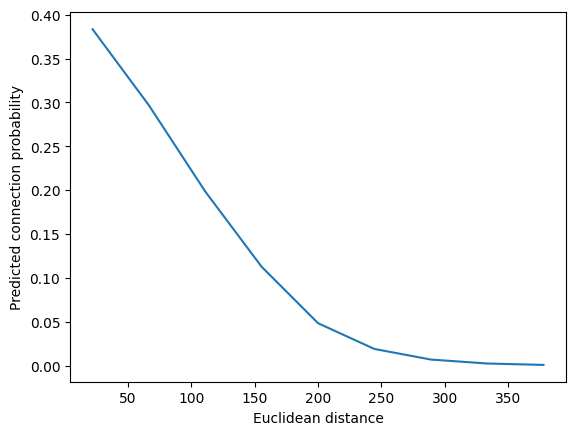

'"res = {}\n\ndist_bins = np.linspace(0, 400, 10)\n\n\n\nfor path, pre, post in pathways:\n\n    pot = potential_connections(pre, post, metric=\'Euclidean\')\n\n    # features pour le MLP\n    X_pot = pot[[\'euclidean\']].values  # + autres features si tu en as\n\n\n    with torch.no_grad():\n        preds = model(torch.tensor(X_pot, dtype=torch.float32)).squeeze().numpy()\n\n    pot = pot.copy()\n    pot[\'pred\'] = preds\n\n    # Bernoulli sampling\n    pot[\'sample\'] = np.random.rand(len(pot)) < pot[\'pred\']\n\n    # garder uniquement les connexions\n    conn = pot[pot[\'sample\']].copy()\n\n\n    c, p, s = compute_connection_probability(conn, pot, \'euclidean\', dist_bins)\n    res[path] = (c, p, s)'

In [42]:
pot = potential_connections(pre, post, metric='Euclidean')

X_pot = pot[['euclidean']].values
X_pot = scaler.transform(pot[['euclidean']].values)

with torch.no_grad():
    preds = model(torch.tensor(X_pot, dtype=torch.float32)).squeeze().cpu().numpy()

pot = pot.copy()
pot['pred'] = preds

dist_bins = np.linspace(0, 400, 10)

pot['bin'] = pd.cut(pot['euclidean'], bins=dist_bins)

group = pot.groupby('bin')

centers = 0.5 * (dist_bins[:-1] + dist_bins[1:])
prob = group['pred'].mean().values
sem = group['pred'].std().values / np.sqrt(group['pred'].count().values)

plt.errorbar(centers, prob, yerr=sem)
plt.xlabel("Euclidean distance")
plt.ylabel("Predicted connection probability")
plt.show()




""""res = {}

dist_bins = np.linspace(0, 400, 10)



for path, pre, post in pathways:

    pot = potential_connections(pre, post, metric='Euclidean')

    # features pour le MLP
    X_pot = pot[['euclidean']].values  # + autres features si tu en as
    

    with torch.no_grad():
        preds = model(torch.tensor(X_pot, dtype=torch.float32)).squeeze().numpy()

    pot = pot.copy()
    pot['pred'] = preds

    # Bernoulli sampling
    pot['sample'] = np.random.rand(len(pot)) < pot['pred']

    # garder uniquement les connexions
    conn = pot[pot['sample']].copy()


    c, p, s = compute_connection_probability(conn, pot, 'euclidean', dist_bins)
    res[path] = (c, p, s)"""



In [43]:
from IPython.display import display, HTML

res_mlp_con_prob_vs_distance = {}
results = []

dist_bins = np.linspace(0, 400, 10)

pathway_labels = {
    "E23_E23": r"$E_{L2/3} \rightarrow E_{L2/3}$",
    "I23_E23": r"$I_{L2/3} \rightarrow E_{L2/3}$",
    "E4_E23":  r"$E_{L4} \rightarrow E_{L2/3}$",
    "I4_E23":  r"$I_{L4} \rightarrow E_{L2/3}$",
    "E23_I23": r"$E_{L2/3} \rightarrow I_{L2/3}$",
    "I23_I23": r"$I_{L2/3} \rightarrow I_{L2/3}$",
    "E4_I23":  r"$E_{L4} \rightarrow I_{L2/3}$",
    "I4_I23":  r"$I_{L4} \rightarrow I_{L2/3}$"
}

for path, pre, post in pathways:

    print("Training model for", path)

    # dataset
    X, y, features = build_dataset(pre, post, synapses)

    # split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # scaling
    scaler = RobustScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)

    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.float32)

    # modèle
    model = MLP()

    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    dataset = TensorDataset(X_train, y_train)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)

    # training
    for epoch in range(2):

        for xb, yb in loader:

            preds = model(xb).squeeze()
            loss = criterion(preds, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    # évaluation
    model.eval()

    with torch.no_grad():
        test_preds = model(X_test).squeeze(dim=1)
        test_bce = criterion(test_preds, y_test).item()

    preds_np = test_preds.cpu().numpy()
    y_np = y_test.cpu().numpy()

    test_auc = roc_auc_score(y_np, preds_np)

    results.append({
        "Pathway": pathway_labels.get(path, path),
        "Test BCE": test_bce,
        "Test AUC": test_auc,
        "# Test Pairs": len(y_test)
    })

    print("AUC:", test_auc)

    # prédictions sur toutes les connexions potentielles
    pot = potential_connections(
        pre,
        post,
        metric="Euclidean"
    )

    X_pot = scaler.transform(
        pot[["euclidean"]].values
    )

    with torch.no_grad():
        preds = model(
            torch.tensor(X_pot, dtype=torch.float32)
        ).squeeze(dim=1).numpy()

    pot = pot.copy()
    pot["pred"] = preds

    pot["bin"] = pd.cut(
        pot["euclidean"],
        bins=dist_bins
    )

    group = pot.groupby(
        "bin",
        observed=False
    )

    centers = 0.5 * (
        dist_bins[:-1] + dist_bins[1:]
    )

    prob = group["pred"].mean().values

    sem = (
        group["pred"].std().values
        / np.sqrt(group["pred"].count().values)
    )

    res_mlp_con_prob_vs_distance[path] = (
        centers,
        prob,
        sem
    )


# Tableau des résultats
results_df = pd.DataFrame(results)

styled_table = (
    results_df.style

    .hide(axis="index")

    .set_caption("Pipeline Antoine")

    .format({
        "Test BCE": "{:.4f}",
        "Test AUC": "{:.4f}",
        "# Test Pairs": "{:,}"
    })

    .set_properties(**{
        "font-family": "Times New Roman, serif",
        "font-size": "18px",
        "text-align": "center",
        "padding": "4px 22px",
        "border": "none",
        "background-color": "white",
        "color": "black"
    })

    .set_table_styles([
        {
            "selector": "table",
            "props": [
                ("border-collapse", "collapse"),
                ("border-top", "1.5px solid black"),
                ("border-bottom", "1.5px solid black"),
                ("margin", "auto"),
                ("background-color", "white")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-family", "Times New Roman, serif"),
                ("font-size", "20px"),
                ("font-weight", "normal"),
                ("padding-bottom", "12px"),
                ("color", "black")
            ]
        },
        {
            "selector": "thead th",
            "props": [
                ("font-family", "Times New Roman, serif"),
                ("font-size", "18px"),
                ("font-weight", "normal"),
                ("text-align", "center"),
                ("padding", "4px 22px"),
                ("border", "none"),
                ("border-bottom", "1.5px solid black"),
                ("background-color", "white"),
                ("color", "black")
            ]
        },
        {
            "selector": "tbody td",
            "props": [
                ("border", "none")
            ]
        }
    ])
)

display(HTML(styled_table.to_html()))

Training model for E23_E23
           pre_pt_root_id     post_pt_root_id      size   euclidean
0      864691134919349258  864691135118235357  0.247705   96.797638
1      864691134919349258  864691135561254369  0.266931  107.779556
2      864691134919349258  864691135740933739  0.582599  209.727554
3      864691134941217635  864691136706310510  0.913022  140.986618
4      864691134941412707  864691135639859515  1.460298  149.726013
...                   ...                 ...       ...         ...
40015  864691137198691137  864691135060075931  0.632229   59.569572
40016  864691137198691137  864691135294227468  0.181531  154.758530
40017  864691137198691137  864691135940339622  1.796980  148.820786
40018  864691137198691137  864691136674275975  0.731043   82.358078
40019  864691137198748993  864691136990915733  0.048736  110.609192

[40020 rows x 4 columns]
metri vaut ['Euclidean']
AUC: 0.8473625589789191
Training model for I23_E23
           pre_pt_root_id     post_pt_root_id      size

Pathway,Test BCE,Test AUC,# Test Pairs
$E_{L2/3} \rightarrow E_{L2/3}$,0.0366,0.8474,"1,105,104"
$I_{L2/3} \rightarrow E_{L2/3}$,0.1607,0.8623,"86,837"
$E_{L4} \rightarrow E_{L2/3}$,0.0375,0.7981,"1,286,755"
$I_{L4} \rightarrow E_{L2/3}$,0.1420,0.9129,"78,942"
$E_{L2/3} \rightarrow I_{L2/3}$,0.0949,0.8827,"109,116"
$I_{L2/3} \rightarrow I_{L2/3}$,0.1470,0.8652,"8,567"
$E_{L4} \rightarrow I_{L2/3}$,0.0483,0.8454,"127,043"
$I_{L4} \rightarrow I_{L2/3}$,0.1242,0.9027,"7,794"


exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9


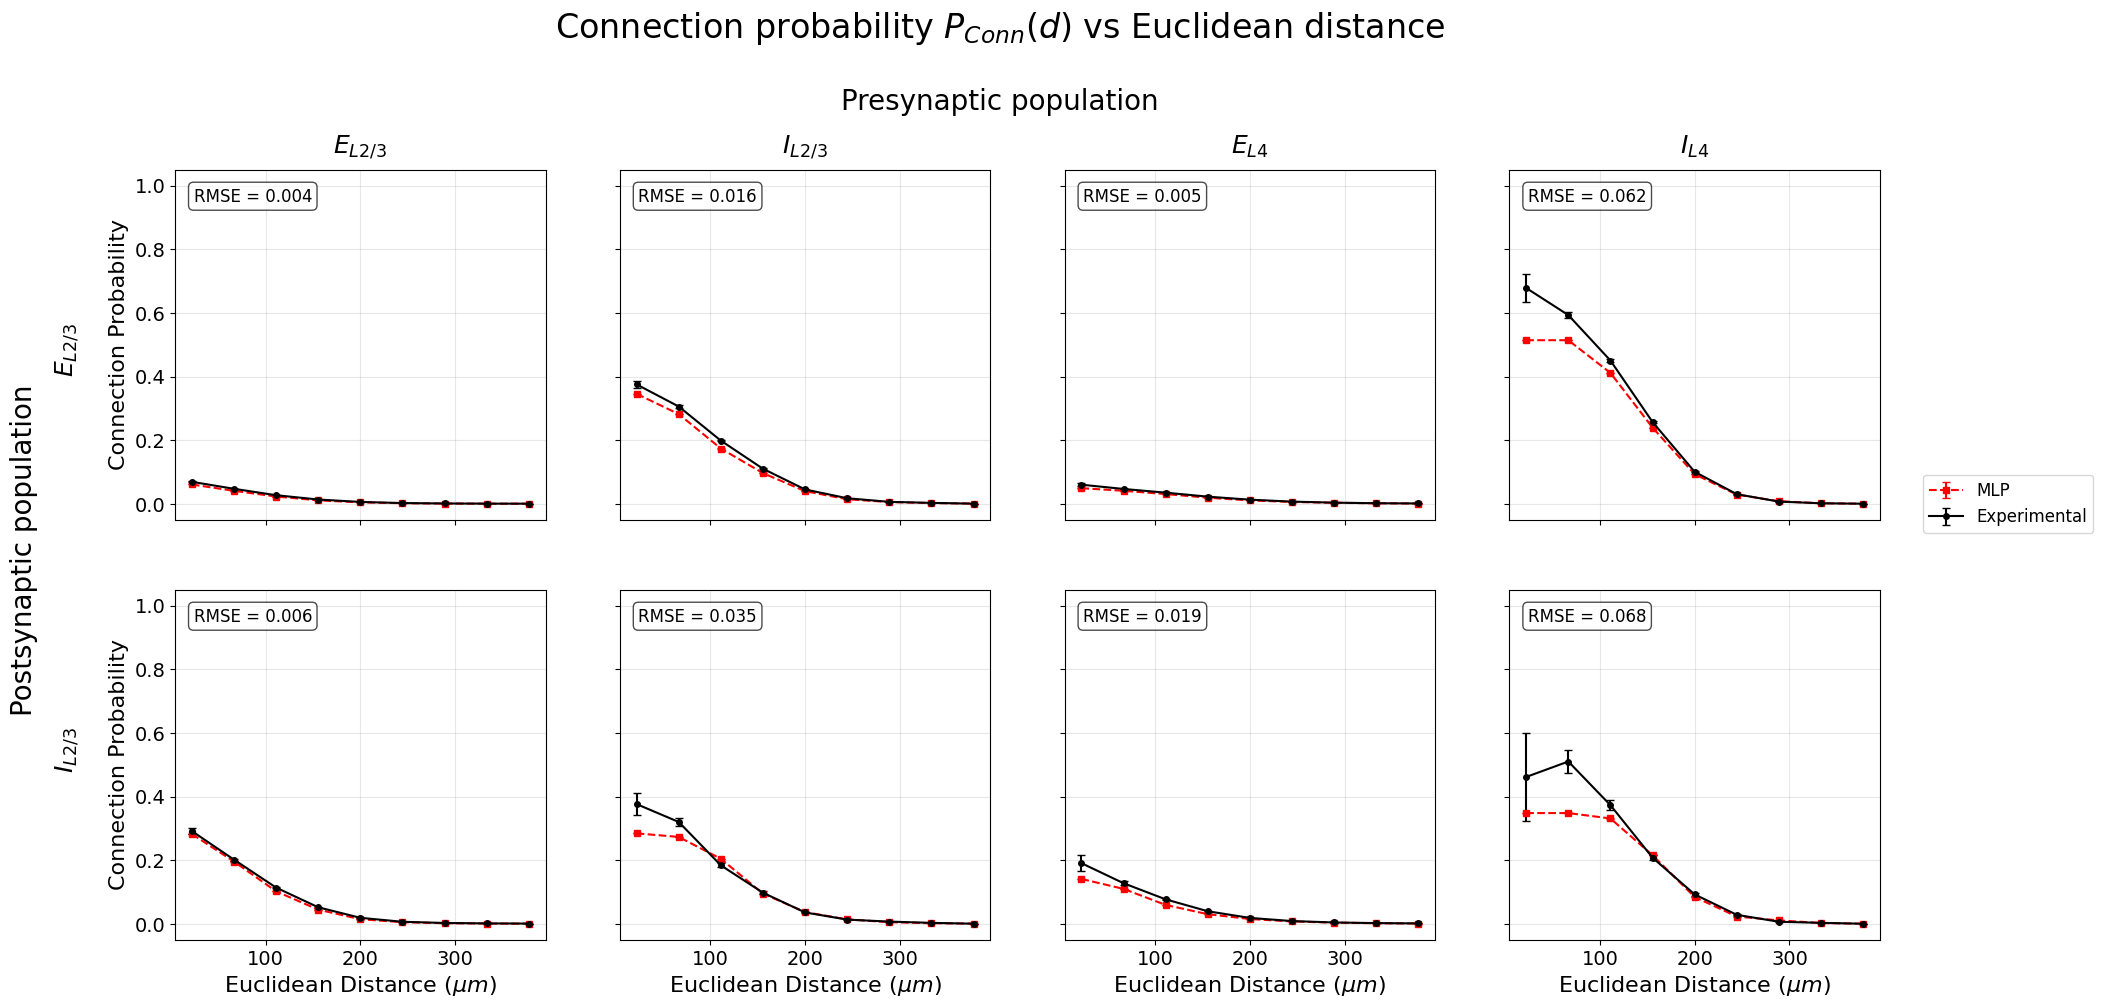

In [44]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)
# -----------------------
# plotting
# -----------------------

for i, (path, prob_mlp) in enumerate(res_mlp_con_prob_vs_distance.items()):
    row = i // 4
    col = i % 4

    centers_mlp, prob_mlp, sem_mlp = prob_mlp
    
    # --- MLP ---
    axs[row, col].errorbar(
        centers_mlp,
        prob_mlp,
        yerr=sem_mlp,
        color='red',
        linestyle='--',
        marker='s',
        markersize=4,
        linewidth=1.5,
        capsize=3,
        label='MLP' if i == 0 else None
    )

    # --- EXP ---
    if path in res_exp_con_prob_vs_distance:
        centers_exp, prob_exp, sem_exp = res_exp_con_prob_vs_distance[path]
        
        print(f"exp : {len(sem_exp)}, mlp : {len(prob_mlp)}")
        
        
        axs[row, col].errorbar(
            centers_exp,
            prob_exp,
            yerr=sem_exp,
            color='black',
            linestyle='-',
            marker='o',
            markersize=4,
            linewidth=1.5,
            capsize=3,
            label='Experimental' if i == 0 else None
        )


        rmse = np.sqrt(np.mean((prob_mlp - prob_exp)**2))
        axs[row, col].text(
            0.05, 0.95,
            f"RMSE = {rmse:.3f}",
            transform=axs[row, col].transAxes,
            fontsize=12,
            verticalalignment='top',
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7)
        )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')
    axs[row, col].set_ylim(-0.05, 1.05)

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Connection Probability", fontsize=16)
axs[1, 0].set_ylabel("Connection Probability", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Connection probability $P_{Conn}(d)$ vs Euclidean distance",
    fontsize=24,
    y=1.04
)
fig.legend(loc='center right', fontsize=12)
fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_Euclidean.png", dpi=300)
plt.show()

In [45]:
path, pre, post = pathways[0]
X, y, features = build_dataset(pre, post, synapses, metric=['Euclidean', 'Ori_Diff'])


           pre_pt_root_id     post_pt_root_id      size  pre_pref_ori_fit  \
0      864691134919349258  864691135561254369  0.266931          1.423603   
1      864691134941495395  864691135639859515  1.986112          0.038310   
2      864691134941495395  864691135994573226  0.212383          0.038310   
3      864691134949221372  864691135993150913  2.588832          0.766602   
4      864691134965778719  864691136124603430  1.762105          0.680730   
...                   ...                 ...       ...               ...   
19283  864691137198382657  864691135475520320  0.400173          0.416383   
19284  864691137198382657  864691136092039348  1.776860          0.416383   
19285  864691137198691137  864691135060075931  0.632229          0.104316   
19286  864691137198691137  864691135294227468  0.181531          0.104316   
19287  864691137198691137  864691136674275975  0.731043          0.104316   

       post_pref_ori_fit   euclidean  ori_diff  ori_diff_polar  
0         

In [46]:
import torch.nn as nn

class MLP_v2(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.net = nn.Sequential(
            nn.Linear(2, 8),
            nn.ReLU(),
            nn.Linear(8, 4),
            nn.ReLU(),
            nn.Linear(4, 1),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.net(x)

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

# scaling
scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

# modèle
model = MLP_v2()

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X_train, y_train)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

for epoch in range(5):
    epoch_loss = 0
    for xb, yb in loader:

        preds = model(xb).squeeze(dim=1)

        loss = criterion(preds, yb)
 
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    print("epoch", epoch, "loss", epoch_loss/len(loader))

with torch.no_grad():
    preds = model(X_test).squeeze()

# IMPORTANT : passer en numpy
preds_np = preds.cpu().numpy()
y_np = y_test.cpu().numpy()

auc = roc_auc_score(y_np, preds_np)

print("AUC:", auc)

epoch 0 loss 0.04854518830472941
epoch 1 loss 0.04698886359645033
epoch 2 loss 0.0469808234669458
epoch 3 loss 0.046970526902031226
epoch 4 loss 0.04697322079770084
AUC: 0.8166135355123612


In [48]:
print(preds.min(), preds.max(), preds.mean())

tensor(2.7805e-06) tensor(0.0794) tensor(0.0096)


In [49]:
res_mlp_con_prob_vs_distance_and_ori_diff = {}

dist_bins = np.linspace(0, 400, 10)

for path, pre, post in pathways:

    print("Training model for", path)

    # dataset
    X, y, features = build_dataset(pre, post, synapses, metric=['Euclidean', 'Ori_Diff'])

    print(X)


    # split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # scaling
    scaler = RobustScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)

    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.float32)

    # modèle
    model = MLP_v2()

    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    dataset = TensorDataset(X_train, y_train)
    loader = DataLoader(dataset, batch_size=32, shuffle=True)

    # training
    for epoch in range(3):
        epoch_loss = 0
        for xb, yb in loader:
            
            preds = model(xb).squeeze(-1)

            loss = criterion(preds, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        
        print("epoch", epoch, "loss", epoch_loss/len(loader))

    with torch.no_grad():
        preds = model(X_test).squeeze(-1)

    preds_np = preds.cpu().numpy()
    y_np = y_test.cpu().numpy()

    auc = roc_auc_score(y_np, preds_np)

    print("AUC:", auc)

    print(f'min pred : {preds.min()}, max pred {preds.max()}, mean pred {preds.mean()}')

    pot = potential_connections_v1(pre, post, metric=['Euclidean','Ori_Diff'])

    X_pot = scaler.transform(pot[['euclidean','ori_diff_polar']].values)

    with torch.no_grad():
        preds = model(torch.tensor(X_pot, dtype=torch.float32)).squeeze(dim=1).numpy()

    pot = pot.copy()
    pot['pred'] = preds

    pot['bin'] = pd.cut(pot['euclidean'], bins=dist_bins)

    group = pot.groupby('bin', observed=False)

    centers = 0.5 * (dist_bins[:-1] + dist_bins[1:])
    prob = group['pred'].mean().values
    sem = group['pred'].std().values / np.sqrt(group['pred'].count().values)

    res_mlp_con_prob_vs_distance_and_ori_diff[path] = (centers, prob, sem)

Training model for E23_E23
           pre_pt_root_id     post_pt_root_id      size  pre_pref_ori_fit  \
0      864691134919349258  864691135561254369  0.266931          1.423603   
1      864691134941495395  864691135639859515  1.986112          0.038310   
2      864691134941495395  864691135994573226  0.212383          0.038310   
3      864691134949221372  864691135993150913  2.588832          0.766602   
4      864691134965778719  864691136124603430  1.762105          0.680730   
...                   ...                 ...       ...               ...   
19283  864691137198382657  864691135475520320  0.400173          0.416383   
19284  864691137198382657  864691136092039348  1.776860          0.416383   
19285  864691137198691137  864691135060075931  0.632229          0.104316   
19286  864691137198691137  864691135294227468  0.181531          0.104316   
19287  864691137198691137  864691136674275975  0.731043          0.104316   

       post_pref_ori_fit   euclidean  ori_diff  

8
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9


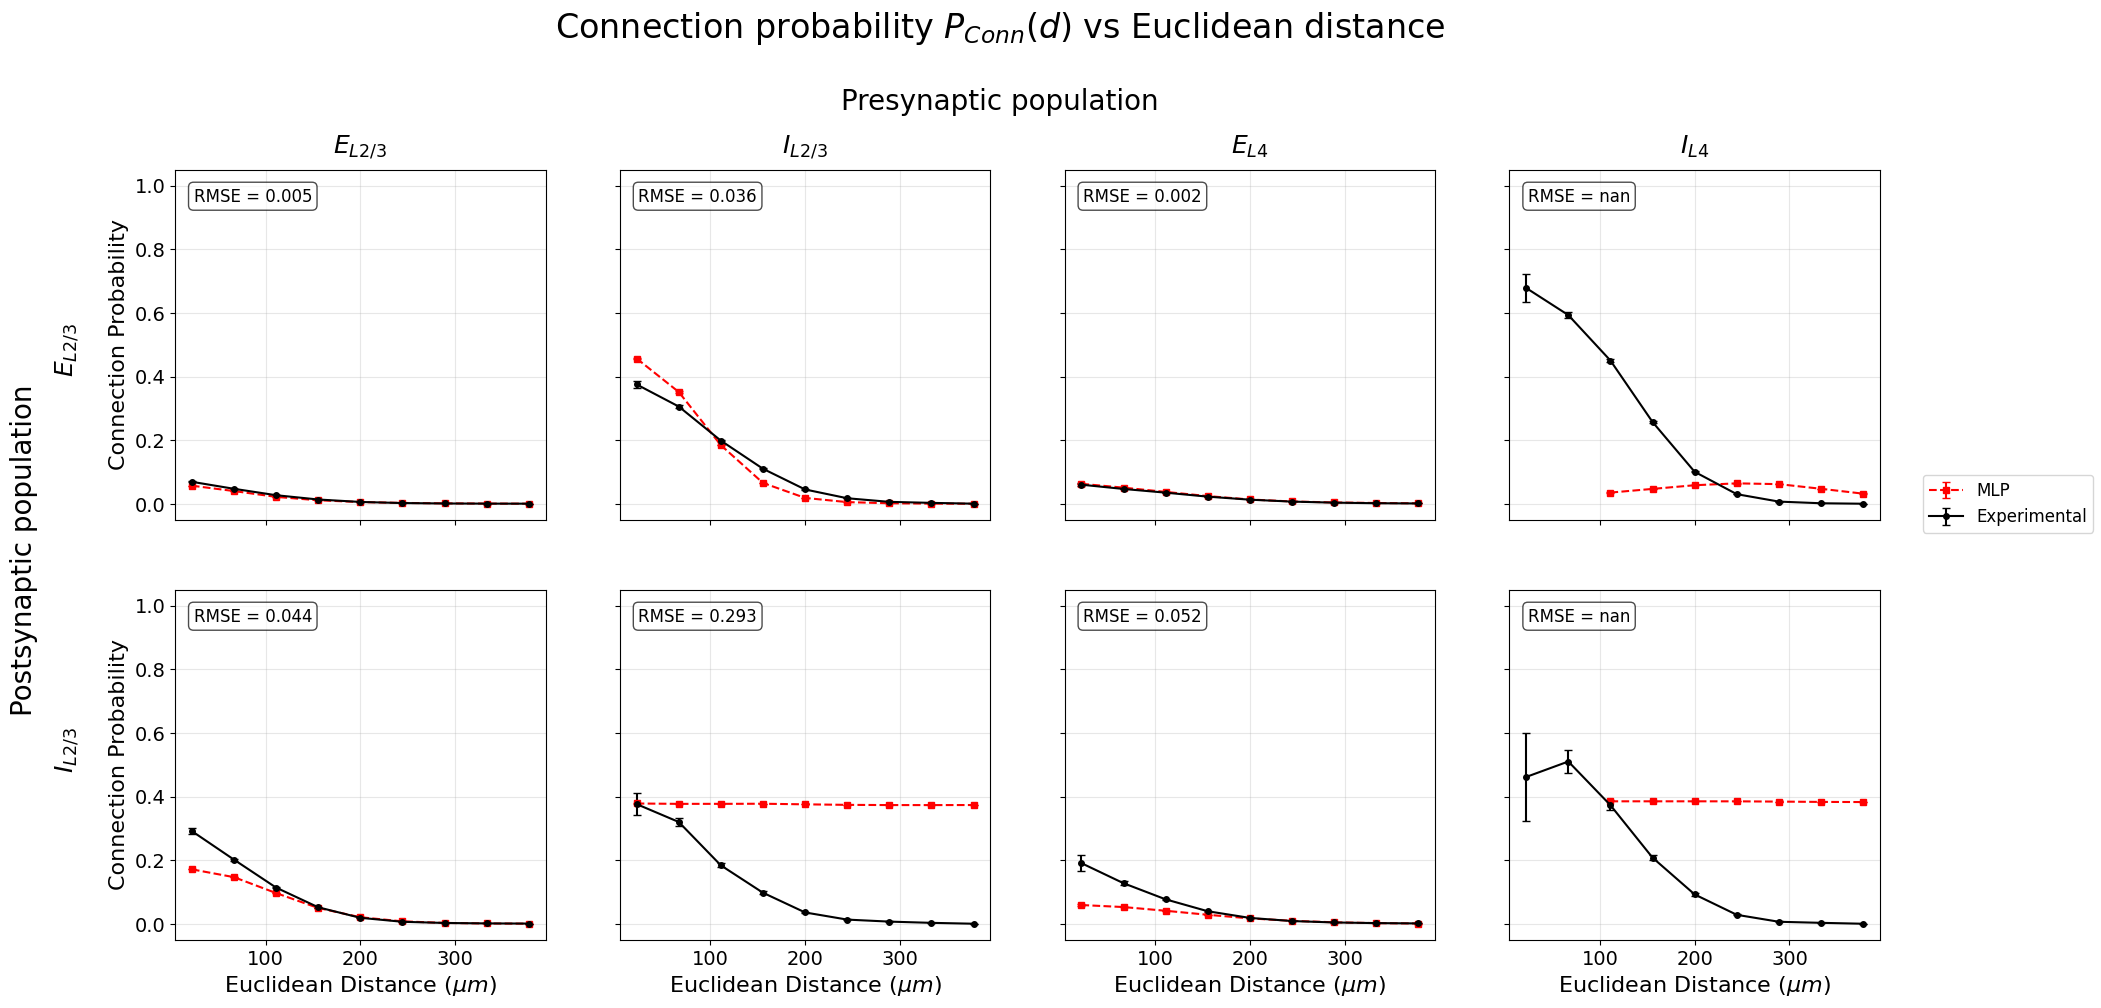

In [50]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)
print(len(res_mlp_con_prob_vs_distance_and_ori_diff))
# -----------------------
# plotting
# -----------------------

for i, (path, prob_mlp) in enumerate(res_mlp_con_prob_vs_distance_and_ori_diff.items()):
    row = i // 4
    col = i % 4

    centers_mlp, prob_mlp, sem_mlp = prob_mlp
    
    # --- MLP ---
    axs[row, col].errorbar(
        centers_mlp,
        prob_mlp,
        yerr=sem_mlp,
        color='red',
        linestyle='--',
        marker='s',
        markersize=4,
        linewidth=1.5,
        capsize=3,
        label='MLP' if i == 0 else None
    )

    # --- EXP ---
    if path in res_mlp_con_prob_vs_distance_and_ori_diff:
        centers_exp, prob_exp, sem_exp = res_exp_con_prob_vs_distance[path]
        
        print(f"exp : {len(sem_exp)}, mlp : {len(prob_mlp)}")
        
        
        axs[row, col].errorbar(
            centers_exp,
            prob_exp,
            yerr=sem_exp,
            color='black',
            linestyle='-',
            marker='o',
            markersize=4,
            linewidth=1.5,
            capsize=3,
            label='Experimental' if i == 0 else None
        )


        rmse = np.sqrt(np.mean((prob_mlp - prob_exp)**2))
        axs[row, col].text(
            0.05, 0.95,
            f"RMSE = {rmse:.3f}",
            transform=axs[row, col].transAxes,
            fontsize=12,
            verticalalignment='top',
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7)
        )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')
    axs[row, col].set_ylim(-0.05, 1.05)

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Connection Probability", fontsize=16)
axs[1, 0].set_ylabel("Connection Probability", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Connection probability $P_{Conn}(d)$ vs Euclidean distance",
    fontsize=24,
    y=1.04
)
fig.legend(loc='center right', fontsize=12)
fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_Euclidean.png", dpi=300)
plt.show()

exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9
exp : 9, mlp : 9


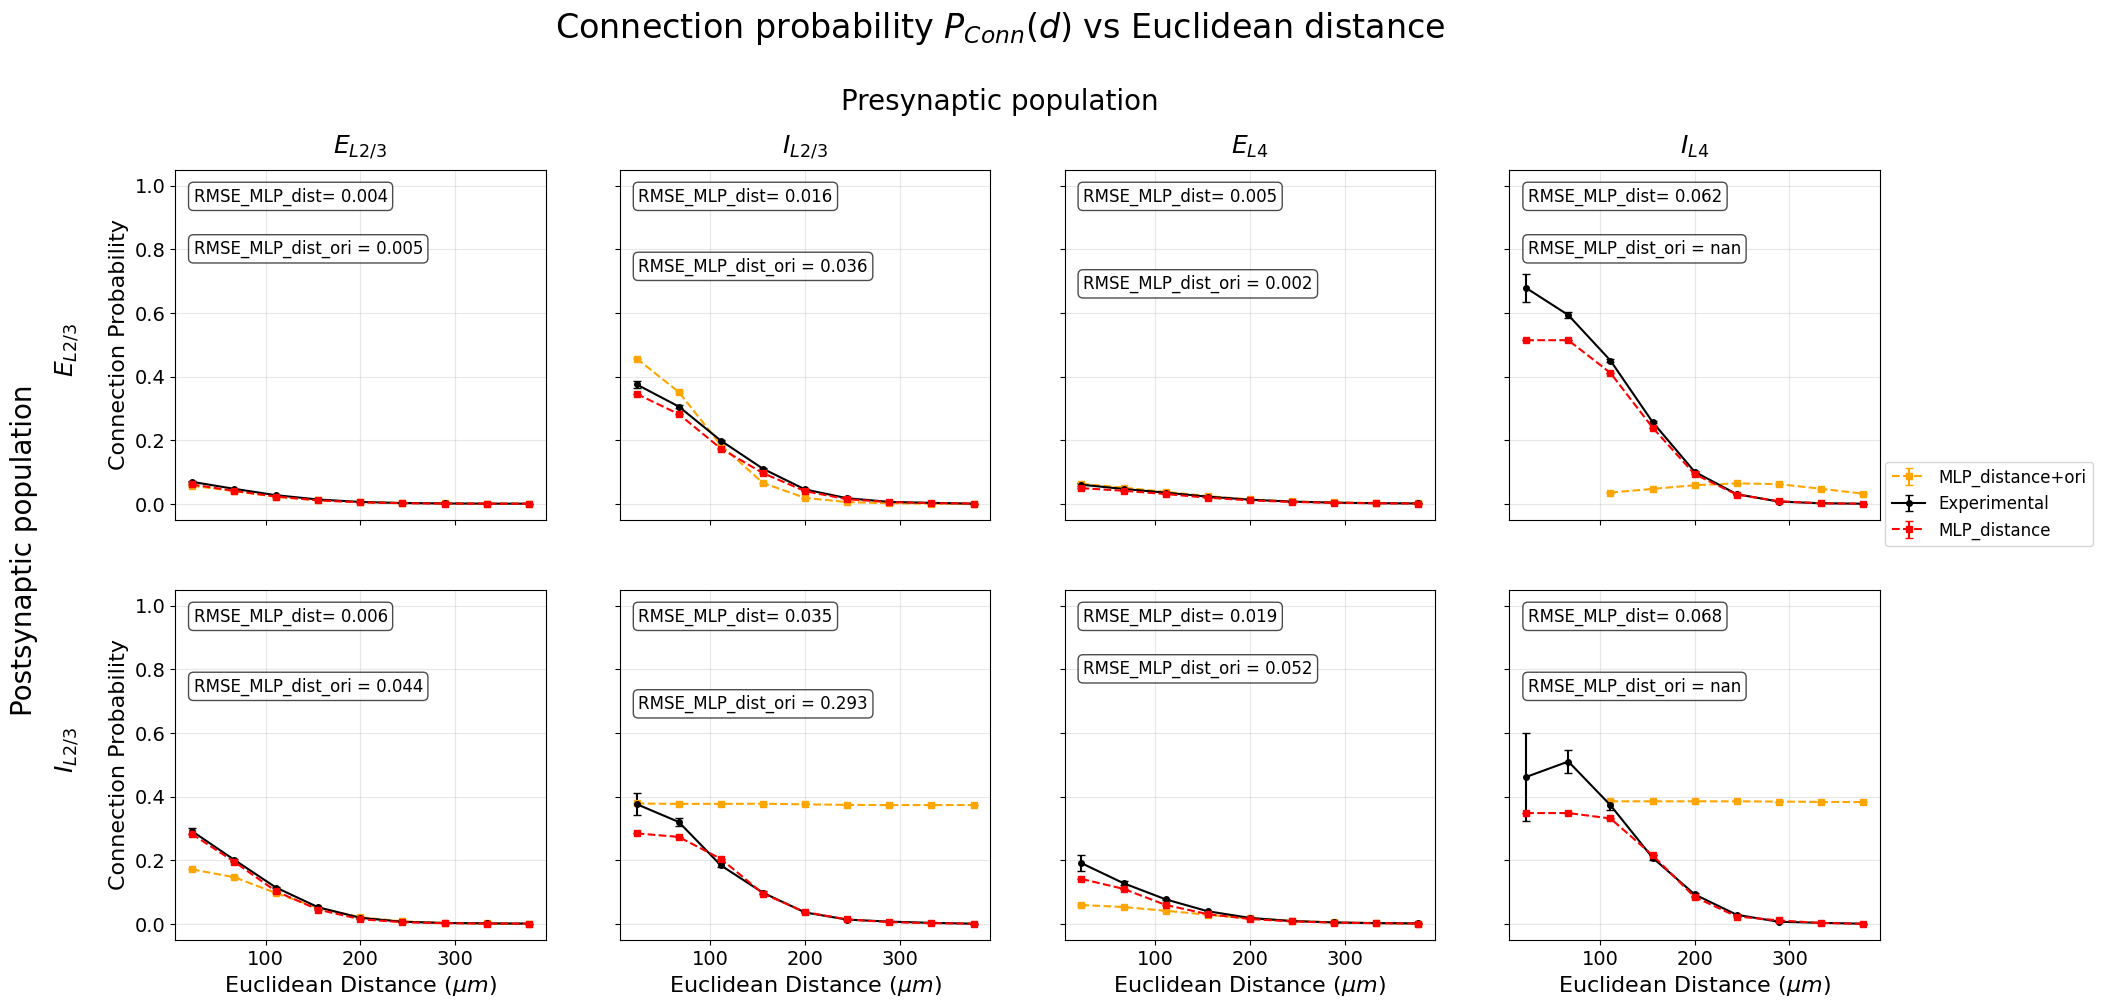

In [51]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)
# -----------------------
# plotting
# -----------------------

for i, (path, prob_mlp) in enumerate(res_mlp_con_prob_vs_distance_and_ori_diff.items()):
    row = i // 4
    col = i % 4

    centers_mlp, prob_mlp, sem_mlp = prob_mlp
    
    # --- MLP ---
    axs[row, col].errorbar(
        centers_mlp,
        prob_mlp,
        yerr=sem_mlp,
        color='orange',
        linestyle='--',
        marker='s',
        markersize=4,
        linewidth=1.5,
        capsize=3,
        label='MLP_distance+ori' if i == 0 else None
    )

    

    if path in res_mlp_con_prob_vs_distance_and_ori_diff:
        centers_exp, prob_exp, sem_exp = res_exp_con_prob_vs_distance[path]
        
        print(f"exp : {len(sem_exp)}, mlp : {len(prob_mlp)}")
        
        
        axs[row, col].errorbar(
            centers_exp,
            prob_exp,
            yerr=sem_exp,
            color='black',
            linestyle='-',
            marker='o',
            markersize=4,
            linewidth=1.5,
            capsize=3,
            label='Experimental' if i == 0 else None
        )


        rmse = np.sqrt(np.mean((prob_mlp - prob_exp)**2))
        axs[row, col].text(
            0.05, 0.80 - 0.05 * (i % 3),
            f"RMSE_MLP_dist_ori = {rmse:.3f}",
            transform=axs[row, col].transAxes,
            fontsize=12,
            verticalalignment='top',
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7)
        )

    # --- EXP ---
    if path in res_mlp_con_prob_vs_distance.keys():
        centers_res_dist, prob_res_dist, sem_res_dist = res_mlp_con_prob_vs_distance[path]
        
        print(f"exp : {len(sem_res_dist)}, mlp : {len(prob_res_dist)}")
        
        
        axs[row, col].errorbar(
            centers_res_dist,
            prob_res_dist,
            yerr=sem_res_dist,
            color='red',
            linestyle='--',
            marker='s',
            markersize=4,
            linewidth=1.5,
            capsize=3,
            label='MLP_distance' if i == 0 else None
        )


        rmse = np.sqrt(np.mean((prob_res_dist - prob_exp)**2))
        axs[row, col].text(
            0.05, 0.95,
            f"RMSE_MLP_dist= {rmse:.3f}",
            transform=axs[row, col].transAxes,
            fontsize=12,
            verticalalignment='top',
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.7)
        )

    axs[row, col].grid(alpha=0.3)
    axs[row, col].tick_params(axis='both', labelsize=14)
    axs[row, col].set_facecolor('white')
    axs[row, col].set_ylim(-0.05, 1.05)

# -----------------------
# axis labels
# -----------------------
for ax in axs[1, :]:
    ax.set_xlabel(r"Euclidean Distance ($\mu m$)", fontsize=16)

axs[0, 0].set_ylabel("Connection Probability", fontsize=16)
axs[1, 0].set_ylabel("Connection Probability", fontsize=16)

# -----------------------
# column titles (presynaptic populations)
# -----------------------
col_titles = [r"$E_{L2/3}$", r"$I_{L2/3}$", r"$E_{L4}$", r"$I_{L4}$"]
for ax, col in zip(axs[0], col_titles):
    ax.set_title(col, fontsize=18, pad=12)

fig.text(0.5, 0.94, "Presynaptic population",
         ha='center', fontsize=20)


fig.text(0.07, 0.70, r"$E_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.07, 0.30, r"$I_{L2/3}$",
         fontsize=18, rotation=90, va='center')
fig.text(0.05, 0.5, "Postsynaptic population",
         fontsize=20, rotation=90, va='center')

plt.suptitle(
    r"Connection probability $P_{Conn}(d)$ vs Euclidean distance",
    fontsize=24,
    y=1.04
)
fig.legend(loc='center right', fontsize=12)
fig.align_ylabels()
plt.subplots_adjust(hspace=0.2, wspace=0.2)
fig.savefig("ConnP_Euclidean.png", dpi=300)
plt.show()

In [52]:
for path, pre, post in pathways
conn = existing_connections_v1("temp", pre,post, synapses, metric=['Euclidean', 'Ori_Diff'])
pot = potential_connections_connections_v1("temp", pre,post, synapses, metric=['Euclidean', 'Ori_Diff'])

print(framework)

SyntaxError: expected ':' (4109294234.py, line 1)

In [ ]:
import matplotlib.pyplot as plt

n = len(pathways)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axs = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
axs = axs.flatten()

for i, (path, pre, post) in enumerate(pathways):

    conn = existing_connections_v1(
        "temp", pre, post, synapses,
        metric=['Euclidean', 'Ori_Diff']
    )

    pot = potential_connections_v1(
        pre, post,
        metric=['Euclidean', 'Ori_Diff']
    )

    conn_n = len(conn)
    pot_n = len(pot)

    axs[i].bar(
        ["Conn", "Pot"],
        [conn_n, pot_n],
        color=["tab:blue", "tab:orange"]
    )

    axs[i].set_title(f"{path}")
    axs[i].set_ylabel("Number of connections")
    axs[i].grid(alpha=0.3)

# remove empty axes
for j in range(i + 1, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()